**Testing Live Tennis**


In [2]:
from langchain_livetennis import LiveTennisToolkit

toolkit = LiveTennisToolkit()
tools = toolkit.get_tools()
tools


[LiveTennisMatchesTool(client=<langchain_livetennis._client.LiveTennisClient object at 0x000001A1DC83B080>),
 LiveTennisMatchTool(client=<langchain_livetennis._client.LiveTennisClient object at 0x000001A1DC83B080>),
 LiveTennisScoreTool(client=<langchain_livetennis._client.LiveTennisClient object at 0x000001A1DC83B080>),
 LiveTennisPlayerSearchTool(client=<langchain_livetennis._client.LiveTennisClient object at 0x000001A1DC83B080>),
 LiveTennisPlayerTool(client=<langchain_livetennis._client.LiveTennisClient object at 0x000001A1DC83B080>),
 LiveTennisFixturesTool(client=<langchain_livetennis._client.LiveTennisClient object at 0x000001A1DC83B080>),
 LiveTennisH2HTool(client=<langchain_livetennis._client.LiveTennisClient object at 0x000001A1DC83B080>),
 LiveTennisArchiveMatchesTool(client=<langchain_livetennis._client.LiveTennisClient object at 0x000001A1DC83B080>),
 LiveTennisArchivePlayersTool(client=<langchain_livetennis._client.LiveTennisClient object at 0x000001A1DC83B080>),
 LiveTen

In [3]:
matches_tool = tools[0]
matches_tool.invoke("upcoming")

'{"data": [{"court": "Court 7", "created_at": "2026-11-24T00:02:27.944434Z", "draw": "doubles", "event_status": null, "event_status_updated_at": null, "format": "BO3", "gender": "men", "has_analysis": false, "has_market": false, "id": 224856, "indoor": false, "is_doubles": true, "is_qualifying": false, "live_at": null, "outcome": null, "players": {"p1": {"archive_player_id": null, "backhand": null, "birthday": null, "country": null, "data_completeness": {"known": null, "missing": [], "note": "doubles team — per-player profile fields do not apply", "of": null}, "hand": null, "id": 41088, "is_doubles_team": true, "itf_ranking": null, "name": "Diaz Enrique Carrascosa / Diaz Maxi Carrascosa", "ranking": null, "ranking_checked_at": null, "ranking_movement": null, "ranking_points": null, "ranking_status": null, "tour": "atp"}, "p2": {"archive_player_id": null, "backhand": null, "birthday": null, "country": null, "data_completeness": {"known": null, "missing": [], "note": "doubles team — per-

In [4]:
from langchain.chat_models import init_chat_model

llm = init_chat_model(model="gpt-5-mini", model_provider="openai", temperature=0.2)

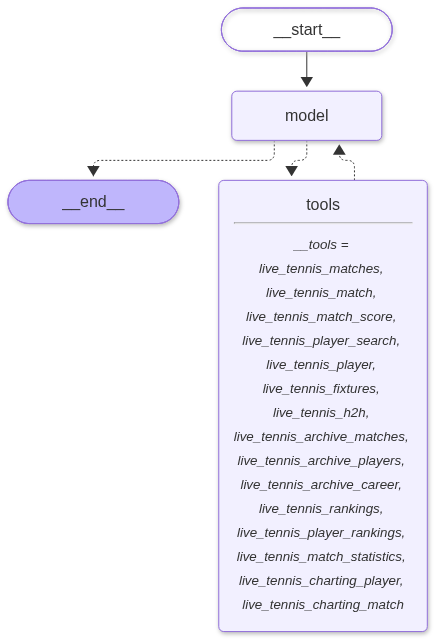

In [6]:
from langchain.agents import create_agent
agent = create_agent(model=llm, tools=tools)
agent

In [ ]:
output = agent.invoke(
    {
        "messages":[
            ('human', 'are there any upcoming matches for Rafael Nadal ?')
        ]
    }
)
output

{'messages': [HumanMessage(content='are there any upcoming matches for Rafael Nadal ?', additional_kwargs={}, response_metadata={}, id='b34e90d4-0737-4969-bee4-3fc2f43dba7a'),
  AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 96, 'prompt_tokens': 2993, 'total_tokens': 3089, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 64, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-5-mini-2025-08-07', 'system_fingerprint': None, 'id': 'chatcmpl-Eo0ZDIJBBtsFxyQOndHmmENgEd14f', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a21157-a140-76b1-9a74-d5f6e84554c9-0', tool_calls=[{'name': 'live_tennis_player_search', 'args': {'search': 'rafael nadal', '

In [ ]:
chunks = agent.stream(
    {
        "messages":[
            ('system','you are helpful AI assistant' )
            ('human', 'are there any upcoming matches for Rafael Nadal ?')
        ]
    },
    stream_mode = "values"
)

for chunk in chunks:
    chunk["messages"][-1].pretty_print()
    

================================ Human Message =================================

are there any upcoming matches for Rafael Nadal ?
================================== Ai Message ==================================
Tool Calls:
  live_tennis_player_search (call_VJoJUAId8XGoM6ZPTkclf1PM)
 Call ID: call_VJoJUAId8XGoM6ZPTkclf1PM
  Args:
    search: rafael nadal
    limit: 5
================================= Tool Message =================================
Name: live_tennis_player_search

{"data": [{"archive_player_id": 104745, "backhand": null, "birthday": "1986-06-03", "country": null, "data_completeness": {"known": 1, "missing": ["backhand", "country", "hand", "ranking"], "of": 5}, "hand": null, "id": 14013, "is_doubles_team": false, "itf_ranking": null, "name": "Rafael Nadal", "profile_restated_at": null, "profile_version": 1, "ranking": null, "ranking_checked_at": "2026-11-25T05:32:46.339430Z", "ranking_movement": null, "ranking_points": null, "ranking_status": "unranked", "tour": "atp"}],

In [ ]:
chunks = agent.stream(
    {
        "messages":[
            ('system','you are helpful AI assistant'),
            ('human', 'Who is Novak Djokovic and give me highlights.')
        ]
    },
    stream_mode = "values"
)

for chunk in chunks:
    chunk["messages"][-1].pretty_print()
    

================================ System Message ================================

Who is Novak Djokovic and give me highlights. 
================================== Ai Message ==================================

Novak Djokovic — short profile and highlights

- Who he is: Novak Djokovic is a Serbian professional tennis player, born 22 May 1987 in Belgrade. He turned pro in 2003 and plays right‑handed with a two‑handed backhand.

- Reputation: Widely regarded as one of the greatest male tennis players in history. Known for exceptional flexibility and movement, an elite return of serve, all‑court consistency, mental toughness and tactical intelligence.

Selected career highlights (selected, non‑exhaustive)
- Grand Slam dominance: Djokovic is a multiple‑time Grand Slam singles champion and one of the most successful male Grand Slam players ever. He has completed a career Grand Slam (winning all four majors) and has repeatedly contended for — and set — major records throughout his career.
- 

In [24]:
chunks = agent.stream(
    {
        "messages":[
            ('system','you are helpful AI assistant'),
            ('human',' can Elena Rybakina win australian open 2027 ? who is her biggest obstacle in the way?')
            
        ]
    },
    stream_mode = "values"
)

for chunk in chunks:
    chunk["messages"][-1].pretty_print()
    

================================ Human Message =================================

 can Elena Rybakina win australian open 2027 ? who is her biggest obstacle in the way?
================================== Ai Message ==================================
Tool Calls:
  live_tennis_player_search (call_9Yq0V2z5pRG3x1pUYdbubI6B)
 Call ID: call_9Yq0V2z5pRG3x1pUYdbubI6B
  Args:
    search: elena rybakina
    limit: 10
================================= Tool Message =================================
Name: live_tennis_player_search

{"data": [{"archive_player_id": 214981, "backhand": null, "birthday": "1999-06-17", "country": "kaz", "data_completeness": {"known": 4, "missing": ["backhand"], "of": 5}, "hand": "R", "id": 47, "is_doubles_team": false, "itf_ranking": null, "name": "Elena Rybakina", "profile_restated_at": null, "profile_version": 1, "ranking": 1, "ranking_checked_at": "2026-11-25T05:32:46.339430Z", "ranking_movement": "same", "ranking_points": 8099, "ranking_status": "ranked", "tour": "w